# 07 — Transfer without labels: what a self-supervised pretext really buys

**Question.** Can a network learn *transferable* features from a task whose
labels are generated from the images themselves — no human annotation at
all? The classic pretext is RotNet (Gidaris, Singh & Komodakis, ICLR 2018):
rotate each image by 0/90/180/270° and train the network to predict which.
To tell rotations apart it must implicitly learn shapes, strokes and parts
— or so the argument goes. (Lineage: context prediction, Doersch et al.
ICCV 2015; today's foundation-model pretraining is the same idea at scale.)

**What we actually test, and what to expect.** Two things the literature
says that are *both* visible at this scale, one flattering and one not:

1. **Where SSL features live matters.** Layers next to the pretext output
   specialize to the pretext (notebook 02's generality→specificity story);
   RotNet's own evaluation protocol probes *mid-network* features, not the
   last layer. Expect a collapse at the final block.
2. **A pretext is not magic.** Whether SSL beats plain supervised training
   depends on the regime — model size, unlabeled-data volume, and how
   expensive labels are (Newell & Deng, CVPR 2020). On easy, centered,
   label-cheap MNIST with a 200k-parameter CNN, expect the pretext to get
   *close* to supervised features, not to beat them.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tllab").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

import tllab
from tllab import analysis, data, models, train

tllab.setup()

src = train.train_or_load_source("mnist:rotpred")
rot_task = data.get_task("mnist:rotpred")
rot_acc = train.evaluate(src, rot_task)
print(f"source rotation-prediction test accuracy: {rot_acc:.3f} "
      "(capped by near-rotation-symmetric digits like 0/1/8)")

mnist_t = data.get_task("mnist")
fashion_t = data.get_task("fashion")
N_LABELS = tllab.q(1000, 100)
mpool = data.subset(mnist_t, tllab.q(6000, 1200), seed=99)
fpool = data.subset(fashion_t, tllab.q(6000, 1200), seed=99)

tllab: torch 2.13.0+cu130 | threads=4 | QUICK=False | root=/home/user/transfer-learning-lab


[ckpt cached] mnist:rotpred: test_acc=0.984


source rotation-prediction test accuracy: 0.984 (capped by near-rotation-symmetric digits like 0/1/8)


## Experiment 1 — probing the pretext encoder depth by depth

Freeze the rotation-trained encoder and train a linear classifier on MNIST
digits (n = 1000 labels) using the representation after each of the five
blocks (conv maps pooled to 4×4, the standard mid-layer probing protocol).
Reference line: training the whole network from scratch on the same 1000
labels. **The encoder below never saw a single digit label.**

[sweep cached] 07_depth_probe.csv


figure -> artifacts/figures/07_depth_probe.png


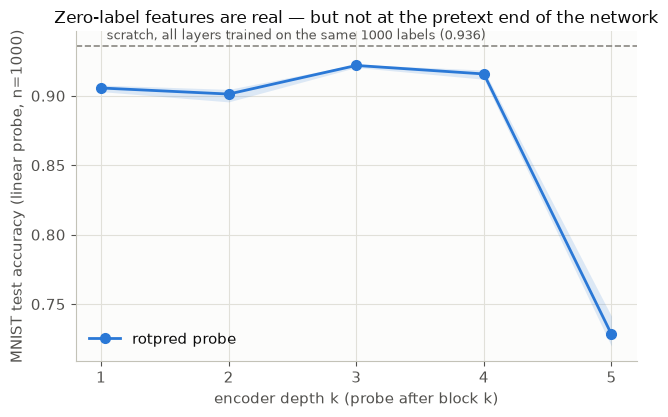

In [2]:
def depth_probe() -> pd.DataFrame:
    rows = []
    for seed in tllab.seeds():
        for k in range(1, 6):
            acc = train.linear_probe(src, mpool, n_train=N_LABELS, seed=seed,
                                     cache_key="07-rotpred", depth=k)
            rows.append({"condition": "rotpred probe", "depth": k,
                         "seed": seed, "acc": acc})
        m = models.new_cnn(10, seed)
        sc = train.fit(m, data.subset(mnist_t, N_LABELS, seed),
                       epochs=tllab.q(15, 2), seed=seed,
                       eval_every=5).final_acc
        rows.append({"condition": "scratch", "depth": 0, "seed": seed,
                     "acc": sc})
        print(f"  seed={seed}: probes "
              + " ".join(f"k{r['depth']}={r['acc']:.3f}"
                         for r in rows[-6:-1]) + f" scratch={sc:.3f}")
    return pd.DataFrame(rows)


df1 = train.cached_sweep("07_depth_probe", depth_probe)
scratch_mnist = df1[df1.condition == "scratch"]["acc"].mean()

plt.figure(figsize=(6.6, 4.3))
ax = plt.gca()
ax.axhline(scratch_mnist, color="#898781", linestyle="--", linewidth=1.2)
ax.annotate(f"scratch, all layers trained on the same {N_LABELS} labels "
            f"({scratch_mnist:.3f})", (1, scratch_mnist),
            textcoords="offset points", xytext=(4, 5), fontsize=9,
            color="#52514e")
analysis.plot_curves(df1[df1.condition == "rotpred probe"], x="depth", y="acc",
                     hue="condition",
                     ylabel="MNIST test accuracy (linear probe, n=1000)",
                     title="Zero-label features are real — but not at the "
                           "pretext end of the network")
ax.set_xlabel("encoder depth k (probe after block k)")
ax.set_xticks(range(1, 6))
analysis.savefig("07_depth_probe")

## Experiment 2 — the same probe across a domain gap

Same protocol at the best depth (k=4), on the pretext's own domain (MNIST)
vs a different domain (Fashion-MNIST). The pretext learned *this domain's*
strokes and shapes, not a universal visual representation — the probe
should lose double digits crossing over. (Notebook 03's matrix showed the
same rule for supervised sources.)

[sweep cached] 07_ssl_vs_supervised.csv


figure -> artifacts/figures/07_ssl_vs_scratch.png


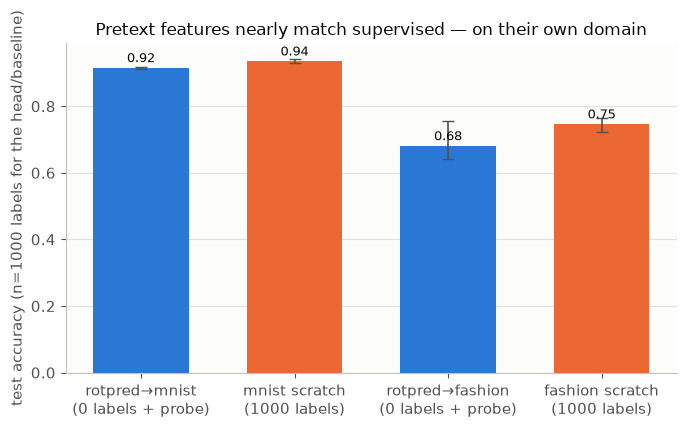

In [3]:
def ssl_vs_supervised() -> pd.DataFrame:
    rows = []
    for tname, task, pool in [("mnist", mnist_t, mpool),
                              ("fashion", fashion_t, fpool)]:
        for seed in tllab.seeds():
            acc = train.linear_probe(src, pool, n_train=N_LABELS, seed=seed,
                                     cache_key="07-rotpred", depth=4)
            rows.append({"target": tname, "condition": "rotpred probe (k=4)",
                         "seed": seed, "acc": acc})
            m = models.new_cnn(10, seed)
            sc = train.fit(m, data.subset(task, N_LABELS, seed),
                           epochs=tllab.q(15, 2), seed=seed,
                           eval_every=5).final_acc
            rows.append({"target": tname, "condition": "scratch", "seed": seed,
                         "acc": sc})
            print(f"  {tname} seed={seed}: probe-k4={rows[-2]['acc']:.3f} "
                  f"scratch={sc:.3f}")
    return pd.DataFrame(rows)


df2 = train.cached_sweep("07_ssl_vs_supervised", ssl_vs_supervised)

g = df2.groupby(["target", "condition"])["acc"]
ORDER = [("mnist", "rotpred probe (k=4)"), ("mnist", "scratch"),
         ("fashion", "rotpred probe (k=4)"), ("fashion", "scratch")]
plt.figure(figsize=(7.0, 4.3))
analysis.plot_bars(
    ["rotpred→mnist\n(0 labels + probe)", "mnist scratch\n(1000 labels)",
     "rotpred→fashion\n(0 labels + probe)", "fashion scratch\n(1000 labels)"],
    [g.mean()[o] for o in ORDER],
    [(g.min()[o], g.max()[o]) for o in ORDER],
    color_idx=[0, 1, 0, 1],
    ylabel=f"test accuracy (n={N_LABELS} labels for the head/baseline)",
    title="Pretext features nearly match supervised — on their own domain")
analysis.savefig("07_ssl_vs_scratch")

## Takeaways

- **Real features from zero labels.** Probing block 3–4 of the
  rotation-trained encoder gets within ~2 points of a fully supervised
  network trained end-to-end on the same 1000 labels — and the encoder
  never saw a digit label. This is the core promise of self-supervision.
- **The pretext eats its own tail.** Features next to the rotation head
  collapse for digit classification (≈17 points below block 4): the last
  block encodes "which way is up", not "which digit". Notebook 02's
  generality→specificity gradient applies to pretext tasks exactly as to
  supervised ones — and it is why RotNet-style evaluation probes
  mid-network layers. If you transfer an SSL encoder, *cut before the
  pretext-specific part*.
- **SSL is domain learning, not universal vision.** The same k=4 probe
  drops ~15 points when pointed at Fashion-MNIST: the pretext learned this
  domain's strokes, and its value fades with domain distance — the matrix
  rule from notebook 03 again.
- **At this scale, the pretext does not beat supervision.** Scratch stays
  ahead at every label budget we tried — consistent with Newell & Deng
  (2020): self-supervised pretraining pays off with bigger models, more
  unlabeled data, harder domains, and expensive labels, none of which hold
  for a 200k-parameter CNN on MNIST. The gap SSL must close here is small
  precisely because the task is easy — the same reason transfer's window
  was narrow in notebook 01.

**References.** Gidaris, Singh & Komodakis, *Unsupervised representation
learning by predicting image rotations* (ICLR 2018). Doersch, Gupta &
Efros, *Unsupervised visual representation learning by context prediction*
(ICCV 2015). Newell & Deng, *How useful is self-supervised pretraining for
visual tasks?* (CVPR 2020). Yosinski et al. (NeurIPS 2014) for the layer
generality gradient.

In [4]:
if not tllab.config.QUICK:
    p = df1[df1.condition == "rotpred probe"].groupby("depth")["acc"].mean()
    best_k = int(p.idxmax())
    analysis.claim("pretext-adjacent collapse: probe k=4 − k=5 > 10 pts",
                   p[4] - p[5] > 0.10, f"{p[4]:.3f} vs {p[5]:.3f}", hard=True)
    analysis.claim("mid-depth probe within 5 pts of supervised scratch",
                   scratch_mnist - p[best_k] < 0.05,
                   f"probe k={best_k} {p[best_k]:.3f} vs scratch "
                   f"{scratch_mnist:.3f}", hard=True)
    g2 = df2.groupby(["target", "condition"])["acc"].mean()
    dm = g2[("mnist", "rotpred probe (k=4)")]
    dfash = g2[("fashion", "rotpred probe (k=4)")]
    analysis.claim("domain gap: k=4 probe mnist − fashion > 5 pts",
                   dm - dfash > 0.05, f"{dm:.3f} vs {dfash:.3f}", hard=True)
    analysis.claim("scratch stays ahead of the probe on its own domain (honest "
                   "negative result at this scale)", scratch_mnist >= dm,
                   f"scratch {scratch_mnist:.3f} vs probe {dm:.3f}")

CLAIM CHECK [PASS] pretext-adjacent collapse: probe k=4 − k=5 > 10 pts — 0.916 vs 0.728
CLAIM CHECK [PASS] mid-depth probe within 5 pts of supervised scratch — probe k=3 0.922 vs scratch 0.936
CLAIM CHECK [PASS] domain gap: k=4 probe mnist − fashion > 5 pts — 0.916 vs 0.681
CLAIM CHECK [PASS] scratch stays ahead of the probe on its own domain (honest negative result at this scale) — scratch 0.936 vs probe 0.916
